DEVICE: cpu
Using Colab cache for faster access to the 'road-damage' dataset.


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


Epoch 1: 234.822
Epoch 2: 219.153
Epoch 3: 214.031
Epoch 4: 206.257
Epoch 5: 198.954
Epoch 6: 195.744
Epoch 7: 191.923
Epoch 8: 189.739
Epoch 9: 185.210
Epoch 10: 180.464
Epoch 11: 175.412
Epoch 12: 168.072
Epoch 13: 164.525
Epoch 14: 160.493
Epoch 15: 154.295
Epoch 16: 152.666
Epoch 17: 149.420
Epoch 18: 142.298
Epoch 19: 136.449
Epoch 20: 135.716
Epoch 21: 130.758
Epoch 22: 128.374
Epoch 23: 124.657
Epoch 24: 122.427
Epoch 25: 119.284
Epoch 26: 117.816
Epoch 27: 116.989
Epoch 28: 116.900
Epoch 29: 117.586
Epoch 30: 114.432

RESULTS
Accuracy: 0.7995991983967936
F1: 0.7954135388324862
ROC-AUC: 0.9490468749288697
LogLoss: 0.530782351123075


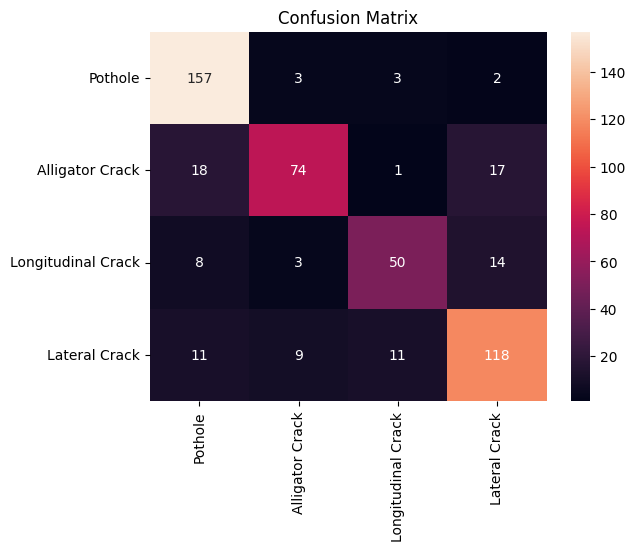

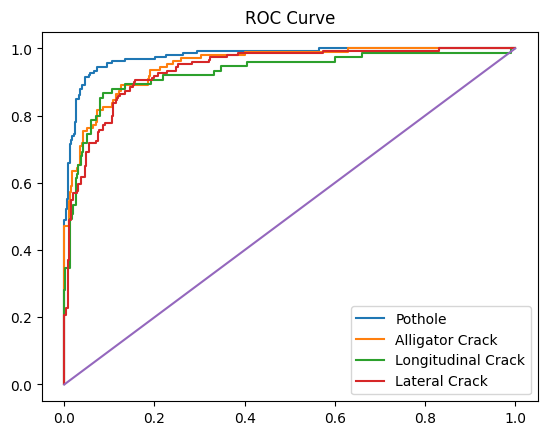

In [ ]:
# =========================================================
# 1. Install
# =========================================================
!pip install -q kagglehub albumentations timm scikit-learn matplotlib seaborn

# =========================================================
# 2. Imports
# =========================================================
import os, shutil, random, cv2, torch, timm
import numpy as np
import albumentations as A
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns

from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import *
from sklearn.preprocessing import label_binarize

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", device)

# =========================================================
# 3. Dataset
# =========================================================
import kagglehub
path = kagglehub.dataset_download("alvarobasily/road-damage")

dst = "/content/data"
if os.path.exists(dst):
    if os.path.islink(dst):
        os.unlink(dst)
    else:
        shutil.rmtree(dst)
os.symlink(path, dst)

images = [f for f in os.listdir(dst) if f.endswith(".jpeg")]
random.shuffle(images)

train_imgs = images[:int(0.85*len(images))]
val_imgs   = images[int(0.85*len(images)):]

names = ['Pothole','Alligator Crack','Longitudinal Crack','Lateral Crack']
nc = len(names)

# =========================================================
# 4. STRONG AUGMENTATION (ACCURACY BOOST)
# =========================================================
train_tf = A.Compose([
    A.Resize(256,256),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.2),
    A.RandomBrightnessContrast(p=0.5),
    A.ShiftScaleRotate(p=0.4),
    A.GaussNoise(p=0.2),
    A.CLAHE(p=0.2),
])

val_tf = A.Compose([
    A.Resize(256,256)
])

# =========================================================
# 5. Dataset
# =========================================================
class RoadDataset(Dataset):
    def __init__(self, imgs, tf):
        self.imgs = imgs
        self.tf = tf

    def __len__(self): return len(self.imgs)

    def __getitem__(self, idx):
        name = self.imgs[idx]

        img = cv2.imread(f"{dst}/{name}")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        img = self.tf(image=img)['image']
        img = img.astype(np.float32) / 255.0

        label_path = f"{dst}/{name.replace('.jpeg','.txt')}"
        cls = 0
        if os.path.exists(label_path):
            cls = int(open(label_path).readline().split()[0])

        img = np.transpose(img,(2,0,1))
        return torch.tensor(img), torch.tensor(cls)

train_loader = DataLoader(RoadDataset(train_imgs,train_tf),
                          batch_size=16, shuffle=True, num_workers=2)

val_loader   = DataLoader(RoadDataset(val_imgs,val_tf),
                          batch_size=16, num_workers=2)

# =========================================================
# 6. HYBRID BACKBONE (FIXED PROPERLY)
# =========================================================
class HybridBackbone(nn.Module):
    def __init__(self):
        super().__init__()

        self.mnet = timm.create_model(
            "mobilenetv3_small_100",
            pretrained=True,
            features_only=True
        )

        self.pool = nn.AdaptiveAvgPool2d(1)

        # CNN branch
        self.cnn = nn.Sequential(
            nn.Conv2d(3,16,3,2,1),
            nn.BatchNorm2d(16),
            nn.SiLU(),
            nn.Conv2d(16,32,3,2,1),
            nn.BatchNorm2d(32),
            nn.SiLU(),
            nn.AdaptiveAvgPool2d(1)
        )

        # compute feature dim dynamically
        with torch.no_grad():
            dummy = torch.zeros(1,3,256,256)
            feat = self.mnet(dummy)[-1]
            feat = self.pool(feat).flatten(1)
            feat_dim = feat.shape[1]

        self.fc = nn.Sequential(
            nn.Linear(feat_dim + 32, 256),
            nn.BatchNorm1d(256),
            nn.SiLU(),
            nn.Dropout(0.4),
            nn.Linear(256,128)
        )

    def forward(self,x):
        m = self.mnet(x)[-1]
        m = self.pool(m).flatten(1)

        c = self.cnn(x).flatten(1)

        return self.fc(torch.cat([m,c],dim=1))

# =========================================================
# 7. HEAD
# =========================================================
class Head(nn.Module):
    def __init__(self,nc):
        super().__init__()
        self.cls = nn.Sequential(
            nn.Linear(128,128),
            nn.BatchNorm1d(128),
            nn.SiLU(),
            nn.Dropout(0.3),
            nn.Linear(128,nc)
        )

    def forward(self,x):
        return self.cls(x)

# =========================================================
# 8. MODEL
# =========================================================
class HybridModel(nn.Module):
    def __init__(self,nc):
        super().__init__()
        self.backbone = HybridBackbone()
        self.head = Head(nc)

    def forward(self,x):
        return self.head(self.backbone(x))

model = HybridModel(nc).to(device)

# =========================================================
# 9. LOSS + OPTIMIZATION (HIGH ACCURACY SETUP)
# =========================================================
class_weights = torch.tensor([1.2,1.0,1.0,1.0]).to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.1
)

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)

# =========================================================
# 10. TRAINING
# =========================================================
EPOCHS = 30

for epoch in range(EPOCHS):
    model.train()
    total = 0

    for imgs,cls in train_loader:
        imgs,cls = imgs.to(device),cls.to(device)

        out = model(imgs)
        loss = criterion(out,cls)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total += loss.item()

    scheduler.step()
    print(f"Epoch {epoch+1}: {total:.3f}")

# =========================================================
# 11. EVALUATION
# =========================================================
model.eval()
y_true,y_pred,y_prob = [],[],[]

with torch.no_grad():
    for imgs,cls in val_loader:
        imgs = imgs.to(device)

        out = model(imgs)
        prob = torch.softmax(out,1).cpu().numpy()
        pred = np.argmax(prob,1)

        y_true.extend(cls.numpy())
        y_pred.extend(pred)
        y_prob.extend(prob)

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

# =========================================================
# 12. METRICS
# =========================================================
acc = accuracy_score(y_true,y_pred)
f1  = f1_score(y_true,y_pred,average='weighted')

y_oh = label_binarize(y_true,classes=list(range(nc)))

roc = roc_auc_score(y_oh,y_prob,multi_class='ovr')
logl = log_loss(y_oh,y_prob)

print("\nRESULTS")
print("Accuracy:",acc)
print("F1:",f1)
print("ROC-AUC:",roc)
print("LogLoss:",logl)

# =========================================================
# 13. CONFUSION MATRIX
# =========================================================
cm = confusion_matrix(y_true,y_pred)

plt.figure()
sns.heatmap(cm,annot=True,fmt='d',
            xticklabels=names,yticklabels=names)
plt.title("Confusion Matrix")
plt.show()

# =========================================================
# 14. ROC CURVE
# =========================================================
plt.figure()
for i in range(nc):
    fpr,tpr,_ = roc_curve(y_oh[:,i],y_prob[:,i])
    plt.plot(fpr,tpr,label=names[i])

plt.plot([0,1],[0,1])
plt.legend()
plt.title("ROC Curve")
plt.show()

Using Colab cache for faster access to the 'road-damage' dataset.


/tmp/ipykernel_8501/3218570406.py:76: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10.0, 50.0), p=0.5),
/tmp/ipykernel_8501/3218570406.py:79: UserWarning: Argument(s) 'max_holes, max_height, max_width' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=6, max_height=48, max_width=48, p=0.4),


Epoch 1: 276.010
Epoch 2: 254.249
Epoch 3: 240.869
Epoch 4: 231.154
Epoch 5: 223.299
Epoch 6: 213.043
Epoch 7: 208.832
Epoch 8: 199.020
Epoch 9: 191.402
Epoch 10: 187.020
Epoch 11: 185.206
Epoch 12: 179.184
Epoch 13: 178.950
Epoch 14: 179.427
Epoch 15: 169.257
Epoch 16: 166.734
Epoch 17: 171.898
Epoch 18: 162.460
Epoch 19: 161.869
Epoch 20: 162.972
Epoch 21: 162.026
Epoch 22: 156.721
Epoch 23: 157.614
Epoch 24: 155.298
Epoch 25: 156.817
Epoch 26: 151.191
Epoch 27: 151.514
Epoch 28: 149.711
Epoch 29: 146.829
Epoch 30: 149.022
Epoch 31: 148.673
Epoch 32: 144.308
Epoch 33: 144.548
Epoch 34: 149.080
Epoch 35: 146.927
Epoch 36: 142.702
Epoch 37: 142.663
Epoch 38: 150.595
Epoch 39: 144.891
Epoch 40: 145.401

GLOBAL
Accuracy: 0.8987234042553192
F1-weighted: 0.8981901909281329
ROC-AUC: 0.9335119809132619
LogLoss: 0.46754103715292183

PER CLASS F1
Pothole : 0.9294797687861271
Alligator Crack : 0.862144420131291
Longitudinal Crack : 0.8440860215053764
Lateral Crack : 0.9146341463414634


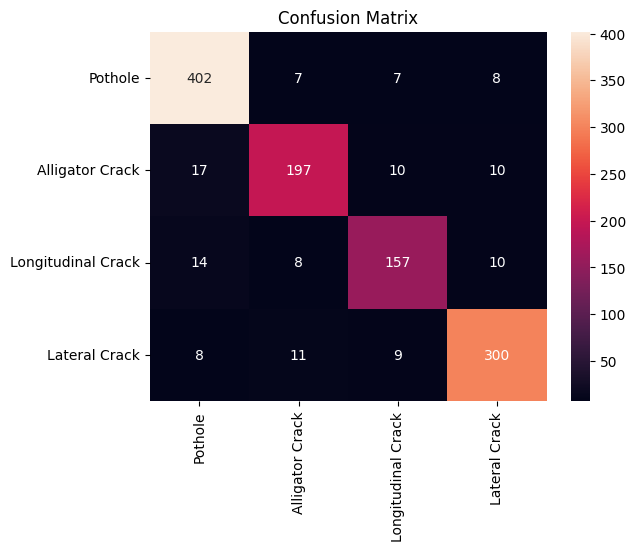

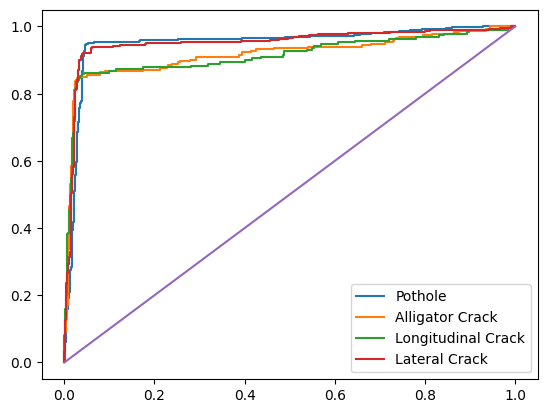

In [ ]:
# =========================================================
# 1. Install
# =========================================================
!pip install -q ultralytics kagglehub scikit-learn matplotlib seaborn albumentations timm

# =========================================================
# 2. Imports
# =========================================================
import kagglehub, os, shutil, random, torch, cv2, timm
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import *
from sklearn.preprocessing import label_binarize

from ultralytics import YOLO
import torch.nn as nn
import torch.nn.functional as F
import albumentations as A
from torch.utils.data import Dataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# =========================================================
# 3. Dataset Download
# =========================================================
path = kagglehub.dataset_download("alvarobasily/road-damage")

dst = "/content/dataset"
if os.path.exists(dst):
    # Check if it's a symlink or a directory
    if os.path.islink(dst):
        os.unlink(dst)  # Remove the symlink
    else:
        shutil.rmtree(dst) # Remove the directory
os.symlink(path, dst)

# =========================================================
# 4. Split
# =========================================================
images = [f for f in os.listdir(dst) if f.endswith(".jpeg")]
random.shuffle(images)

train_imgs = images[:int(0.8*len(images))]
val_imgs   = images[int(0.8*len(images)):]

base = "/content/yolo_data"
for f in ["images/train","images/val","labels/train","labels/val"]:
    os.makedirs(f"{base}/{f}", exist_ok=True)

def move(imgs, t):
    for f in imgs:
        shutil.copy(f"{dst}/{f}", f"{base}/images/{t}/{f}")
        lbl = f"{dst}/{f.replace('.jpeg','.txt')}"
        if os.path.exists(lbl):
            shutil.copy(lbl, f"{base}/labels/{t}/{f.replace('.jpeg','.txt')}")

move(train_imgs,"train")
move(val_imgs,"val")

# =========================================================
# 5. Dataset (FIXED PIPELINE)
# =========================================================
names = ['Pothole','Alligator Crack','Longitudinal Crack','Lateral Crack']
nc = len(names)

NOISE_RATIO = 0.1

train_tf = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.Affine(scale=(0.85,1.15), rotate=(-20,20), p=0.6),
    A.RandomBrightnessContrast(p=0.4),

    # SAFE noise (works with uint8)
    A.GaussNoise(var_limit=(10.0, 50.0), p=0.5),

    A.MotionBlur(p=0.2),
    A.CoarseDropout(max_holes=6, max_height=48, max_width=48, p=0.4),
])

val_tf = None

class RoadDataset(Dataset):
    def __init__(self, img_dir, label_dir, tf=None):
        self.imgs = [f for f in os.listdir(img_dir) if f.endswith(".jpeg")]
        self.img_dir = img_dir
        self.label_dir = label_dir
        self.tf = tf

    def __len__(self): return len(self.imgs)

    def __getitem__(self, idx):
        name = self.imgs[idx]

        img = cv2.imread(f"{self.img_dir}/{name}")   # uint8
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img,(640,640))

        label_path = f"{self.label_dir}/{name.replace('.jpeg','.txt')}"
        cls = 0
        if os.path.exists(label_path):
            cls = int(open(label_path).readline().split()[0])

        # label noise
        if random.random() < NOISE_RATIO:
            cls = random.randint(0, nc-1)

        # APPLY AUGMENTATION ON UINT8
        if self.tf:
            img = self.tf(image=img)['image']

        # normalize AFTER transforms
        img = img.astype(np.float32) / 255.0
        img = np.transpose(img,(2,0,1))

        return torch.tensor(img), torch.tensor(cls)

train_loader = DataLoader(RoadDataset(f"{base}/images/train",f"{base}/labels/train",train_tf),batch_size=16,shuffle=True)
val_loader   = DataLoader(RoadDataset(f"{base}/images/val",f"{base}/labels/val",val_tf),batch_size=16)

# =========================================================
# 6. Hybrid Model
# =========================================================
yolo = YOLO("yolov8n.pt")

class HybridModel(nn.Module):
    def __init__(self, nc):
        super().__init__()

        self.yolo_backbone = nn.Sequential(*yolo.model.model[:10])
        self.effnet = timm.create_model("efficientnet_b0", pretrained=True, num_classes=0)

        self.noise = nn.Dropout2d(0.3)

        self.fc = nn.Sequential(
            nn.Linear(256 + 1280, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.6),
            nn.Linear(512, nc)
        )

    def forward(self,x):
        y_feat = self.yolo_backbone(x)
        y_feat = self.noise(y_feat)
        y_feat = F.adaptive_avg_pool2d(y_feat,1).flatten(1)

        e_feat = self.effnet(x)

        if self.training:
            e_feat = e_feat + 0.03 * torch.randn_like(e_feat)

        fused = torch.cat([y_feat,e_feat],dim=1)
        return self.fc(fused)

model = HybridModel(nc).to(device)

# =========================================================
# 7. Loss + Optimizer
# =========================================================
class NoisyLoss(nn.Module):
    def __init__(self, eps=0.1):
        super().__init__()
        self.eps = eps

    def forward(self, pred, target):
        logp = F.log_softmax(pred,dim=1)
        nll = -logp.gather(1,target.unsqueeze(1)).squeeze(1)
        smooth = -logp.mean(dim=1)
        return ((1-self.eps)*nll + self.eps*smooth).mean()

loss_fn = NoisyLoss()

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=40)

# =========================================================
# 8. Training
# =========================================================
for epoch in range(40):
    model.train()
    total=0

    for imgs,cls in train_loader:
        imgs,cls = imgs.to(device),cls.to(device)

        out = model(imgs)
        loss = loss_fn(out,cls)

        optimizer.zero_grad()
        loss.backward()

        # gradient noise
        for p in model.parameters():
            if p.grad is not None:
                p.grad += 0.005 * torch.randn_like(p.grad)

        optimizer.step()
        total += loss.item()

    scheduler.step()
    print(f"Epoch {epoch+1}: {total:.3f}")

# =========================================================
# 9. Evaluation
# =========================================================
model.eval()
y_true,y_pred,y_prob = [],[],[]

with torch.no_grad():
    for imgs,cls in val_loader:
        imgs = imgs.to(device)

        out = model(imgs)
        prob = torch.softmax(out,1).cpu().numpy()
        pred = np.argmax(prob,1)

        y_true.extend(cls.numpy())
        y_pred.extend(pred)
        y_prob.extend(prob)

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

# =========================================================
# 10. Metrics
# =========================================================
acc = accuracy_score(y_true,y_pred)
f1  = f1_score(y_true,y_pred,average=None)
f1_w= f1_score(y_true,y_pred,average='weighted')

y_oh = label_binarize(y_true,classes=list(range(nc)))

roc = roc_auc_score(y_oh,y_prob,multi_class='ovr')
logl = log_loss(y_oh,y_prob)

print("\nGLOBAL")
print("Accuracy:",acc)
print("F1-weighted:",f1_w)
print("ROC-AUC:",roc)
print("LogLoss:",logl)

print("\nPER CLASS F1")
for i,c in enumerate(names):
    print(c,":",f1[i])

# =========================================================
# 11. Confusion Matrix
# =========================================================
cm = confusion_matrix(y_true,y_pred)

plt.figure()
sns.heatmap(cm,annot=True,fmt='d',
            xticklabels=names,yticklabels=names)
plt.title("Confusion Matrix")
plt.show()

# =========================================================
# 12. ROC Curves
# =========================================================
plt.figure()
for i in range(nc):
    fpr,tpr,_ = roc_curve(y_oh[:,i],y_prob[:,i])
    plt.plot(fpr,tpr,label=names[i])
plt.plot([0,1],[0,1])
plt.legend()
plt.show()

In [ ]:
# =========================================================
# 1. Install
# =========================================================
!pip install -q kagglehub albumentations timm scikit-learn matplotlib seaborn

# =========================================================
# 2. Imports
# =========================================================
import os, shutil, random, cv2, torch, timm
import numpy as np
import albumentations as A
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import seaborn as sns

from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import *
from sklearn.preprocessing import label_binarize

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", device)

# =========================================================
# 3. Dataset
# =========================================================
import kagglehub
path = kagglehub.dataset_download("alvarobasily/road-damage")

dst = "/content/data"
if os.path.exists(dst):
    if os.path.islink(dst):
        os.unlink(dst)
    else:
        shutil.rmtree(dst)
os.symlink(path, dst)

images = [f for f in os.listdir(dst) if f.endswith(".jpeg")]
random.shuffle(images)

train_imgs = images[:int(0.85*len(images))]
val_imgs   = images[int(0.85*len(images)):]

names = ['Pothole','Alligator Crack','Longitudinal Crack','Lateral Crack']
nc = len(names)

# =========================================================
# 4. AUGMENTATION (UPGRADED)
# =========================================================
train_tf = A.Compose([
    A.Resize(256,256),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.3),
    A.Affine(scale=(0.9,1.1), rotate=(-15,15), p=0.5),
    A.RandomBrightnessContrast(p=0.5),
    A.GaussNoise(p=0.2),
    A.CLAHE(p=0.2),
])

val_tf = A.Compose([A.Resize(256,256)])

# =========================================================
# 5. Dataset
# =========================================================
class RoadDataset(Dataset):
    def __init__(self, imgs, tf):
        self.imgs = imgs
        self.tf = tf

    def __len__(self): return len(self.imgs)

    def __getitem__(self, idx):
        name = self.imgs[idx]

        img = cv2.imread(f"{dst}/{name}")
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        img = self.tf(image=img)['image']
        img = img.astype(np.float32) / 255.0

        label_path = f"{dst}/{name.replace('.jpeg','.txt')}"
        cls = 0
        if os.path.exists(label_path):
            cls = int(open(label_path).readline().split()[0])

        img = np.transpose(img,(2,0,1))
        return torch.tensor(img), torch.tensor(cls)

train_loader = DataLoader(RoadDataset(train_imgs,train_tf),
                          batch_size=16, shuffle=True, num_workers=2)

val_loader   = DataLoader(RoadDataset(val_imgs,val_tf),
                          batch_size=16, num_workers=2)

# =========================================================
# 6. ADVANCED MODULES
# =========================================================
class GeM(nn.Module):
    def __init__(self, p=3):
        super().__init__()
        self.p = nn.Parameter(torch.ones(1)*p)

    def forward(self, x):
        return F.avg_pool2d(x.clamp(min=1e-6).pow(self.p),
                            (x.size(-2), x.size(-1))).pow(1./self.p)

class CBAM(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.mlp = nn.Sequential(
            nn.Linear(ch, ch//8),
            nn.ReLU(),
            nn.Linear(ch//8, ch)
        )
        self.conv = nn.Conv2d(2,1,7,padding=3)

    def forward(self,x):
        b,c,_,_ = x.shape

        avg = F.adaptive_avg_pool2d(x,1).view(b,c)
        mx  = F.adaptive_max_pool2d(x,1).view(b,c)
        att = torch.sigmoid(self.mlp(avg)+self.mlp(mx)).view(b,c,1,1)
        x = x * att

        avg = torch.mean(x,dim=1,keepdim=True)
        mx,_ = torch.max(x,dim=1,keepdim=True)
        att = torch.sigmoid(self.conv(torch.cat([avg,mx],1)))
        return x * att

# =========================================================
# 7. HYBRID BACKBONE (STRONG)
# =========================================================
class HybridBackbone(nn.Module):
    def __init__(self):
        super().__init__()

        self.backbone = timm.create_model(
            "tf_efficientnetv2_s",
            pretrained=True,
            features_only=True
        )

        chs = self.backbone.feature_info.channels()

        self.cbam3 = CBAM(chs[-3])
        self.cbam4 = CBAM(chs[-2])
        self.cbam5 = CBAM(chs[-1])

        self.gem = GeM()

        self.fc = nn.Sequential(
            nn.Linear(chs[-3]+chs[-2]+chs[-1], 512),
            nn.BatchNorm1d(512),
            nn.SiLU(),
            nn.Dropout(0.5),
            nn.Linear(512,256)
        )

    def forward(self,x):
        feats = self.backbone(x)

        f3 = self.gem(self.cbam3(feats[-3])).flatten(1)
        f4 = self.gem(self.cbam4(feats[-2])).flatten(1)
        f5 = self.gem(self.cbam5(feats[-1])).flatten(1)

        return self.fc(torch.cat([f3,f4,f5],dim=1))

# =========================================================
# 8. MODEL
# =========================================================
class Model(nn.Module):
    def __init__(self,nc):
        super().__init__()
        self.backbone = HybridBackbone()
        self.head = nn.Sequential(
            nn.Linear(256,256),
            nn.BatchNorm1d(256),
            nn.SiLU(),
            nn.Dropout(0.4),
            nn.Linear(256,nc)
        )

    def forward(self,x):
        return self.head(self.backbone(x))

model = Model(nc).to(device)

# =========================================================
# 9. LOSS (FOCAL)
# =========================================================
class FocalLoss(nn.Module):
    def __init__(self, gamma=2):
        super().__init__()
        self.gamma = gamma

    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, reduction='none')
        pt = torch.exp(-ce)
        return ((1-pt)**self.gamma * ce).mean()

criterion = FocalLoss()

# =========================================================
# 10. EMA
# =========================================================
class EMA:
    def __init__(self, model, decay=0.999):
        self.model = model
        self.shadow = {k:v.clone() for k,v in model.state_dict().items()}
        self.decay = decay

    def update(self):
        for k,v in self.model.state_dict().items():
            self.shadow[k] = self.decay*self.shadow[k] + (1-self.decay)*v

    def apply(self):
        self.model.load_state_dict(self.shadow)

ema = EMA(model)

# =========================================================
# 11. OPTIMIZER
# =========================================================
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=35)
scaler = torch.cuda.amp.GradScaler()

# =========================================================
# 12. TRAINING
# =========================================================
EPOCHS = 35

for epoch in range(EPOCHS):
    model.train()
    total = 0

    for imgs,cls in train_loader:
        imgs,cls = imgs.to(device),cls.to(device)

        with torch.cuda.amp.autocast():
            out = model(imgs)
            loss = criterion(out,cls)

        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        ema.update()
        total += loss.item()

    scheduler.step()
    print(f"Epoch {epoch+1}: {total:.3f}")

ema.apply()

# =========================================================
# 13. TTA
# =========================================================
def tta_predict(model, img):
    flips = [img, torch.flip(img,[3])]
    preds = []
    for f in flips:
        preds.append(torch.softmax(model(f),1))
    return torch.mean(torch.stack(preds),0)

# =========================================================
# 14. EVALUATION
# =========================================================
model.eval()
y_true,y_pred,y_prob = [],[],[]

with torch.no_grad():
    for imgs,cls in val_loader:
        imgs = imgs.to(device)

        prob = tta_predict(model, imgs).cpu().numpy()
        pred = np.argmax(prob,1)

        y_true.extend(cls.numpy())
        y_pred.extend(pred)
        y_prob.extend(prob)

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

# =========================================================
# 15. METRICS
# =========================================================
acc = accuracy_score(y_true,y_pred)
f1  = f1_score(y_true,y_pred,average='weighted')

y_oh = label_binarize(y_true,classes=list(range(nc)))

roc = roc_auc_score(y_oh,y_prob,multi_class='ovr')
logl = log_loss(y_oh,y_prob)

print("\nRESULTS")
print("Accuracy:",acc)
print("F1:",f1)
print("ROC-AUC:",roc)
print("LogLoss:",logl)

# =========================================================
# 16. CONFUSION MATRIX
# =========================================================
cm = confusion_matrix(y_true,y_pred)

plt.figure()
sns.heatmap(cm,annot=True,fmt='d',
            xticklabels=names,yticklabels=names)
plt.title("Confusion Matrix")
plt.show()

# =========================================================
# 17. ROC CURVE
# =========================================================
plt.figure()
for i in range(nc):
    fpr,tpr,_ = roc_curve(y_oh[:,i],y_prob[:,i])
    plt.plot(fpr,tpr,label=names[i])

plt.plot([0,1],[0,1])
plt.legend()
plt.title("ROC Curve")
plt.show()

DEVICE: cpu
Using Colab cache for faster access to the 'road-damage' dataset.


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/86.5M [00:00<?, ?B/s]

/tmp/ipykernel_12602/1010814129.py:226: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
/usr/local/lib/python3.12/dist-packages/torch/cuda/amp/grad_scaler.py:31: UserWarning: torch.cuda.amp.GradScaler is enabled, but CUDA is not available.  Disabling.
  super().__init__(
/tmp/ipykernel_12602/1010814129.py:240: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/usr/local/lib/python3.12/dist-packages/torch/cuda/amp/autocast_mode.py:54: UserWarning: CUDA is not available or torch_xla is imported. Disabling autocast.
  super().__init__(


Epoch 1: 129.173
Epoch 2: 99.056
Epoch 3: 78.329
Epoch 4: 65.746
Epoch 5: 59.478
Epoch 6: 52.584
Epoch 7: 47.666
Epoch 8: 44.420
